**Bitácora · Day 3 PrefixSpan (chestpain)**

- **v1** `Day3_prefixspan_v1`  
  PrefixSpan on group tags, visits kept; KMeans clusters + SPADE. *Files:* `patterns_chestpain.json`
- **v2** `Day3_prefixspan_v2`  
  Motifs per visit-pruned NMF component; psych-vs-troponin timing. *Files:* `nmf_k8_chestpain_v2.npz`
- **v3 hybrid** `Day3_prefixspan_v3_hybrid` (2026-10-06)  
  v2 + deterministic ties, held-out pass rate, same-day flag, Excel export. *Files:* `nmf_k8_chestpain_v2.npz`, `Day3_v3_hybrid_top3_patterns_table.xlsx`
- **v3 concept** `Day3_prefixspan_v3_concept` (2026-10-07) ← **this notebook**  
  Hybrid on concept-level tokens; k=7 bundles named directly (v2 matching only for other k). *Files:* `nmf_k8_chestpain_v3.npz`, `Day3_v3_concept_final_table_chestpain_k{K}.xlsx`, `token_map_chestpain_concept.csv`

# Day 3 · v3 hybrid · concept-level tokens — sequence motifs inside the visit-pruned NMF components (dx_9487)

**Today's goal:** mine ordered motifs *within each of the NMF components* from `Day1_nmf_v3`,
on event streams with every visit event removed (care-driven bias). Same PrefixSpan as v1; what
changes is the input (no visit tokens) and the groups (v2 components instead of KMeans clusters).

Why: Day 1 v2 told us *which codes co-occur*; the open question from the review is *in what order*
for the two competing explanations of dx_9487 (cardiac workup vs anxiety/panic), and whether any
bundle is really about the condition rather than the care setting.


> **v3 hybrid = this v2 notebook + three additions; v2 itself is untouched.** (Same additions as the letrozole hybrid; the `motif_robustness` helpers are imported from `../repr_learn_letrozole`.)
> 1. **Deterministic ties** — PrefixSpan counts and every sort break ties on the pattern, so two runs give the same motifs.
> 2. **Section 2c · held-out pass rate** — share of 20 random 50/50 splits × 2 directions (40 runs) in which a motif still passes on the half it was *not* scored on; also family-level (near-duplicates vote as one).
> 3. **Same-day flag** — support re-counted with a strictly-later-date rule; a motif whose support collapses is a same-day bundle (co-occurrence), not an evidenced order.
> A final cell writes the top-3 patterns table to Excel. v2 has no bootstrap / re-test columns for this cohort, so the table has no lift range or re-test count.

> **Day 3 v3 concept = the v3 hybrid on concept-level tokens; the group-token hybrid is untouched.**
> `tag_events(..., token_level="concept")`: every event is its own token (`<name20>__<class>__<concept_id>`); the curated group lives in
> `events.group`. The NMF cache is `nmf_k8_chestpain_v3.npz` (written by `Day1_nmf_v3`, or fitted here if missing). Component numbers can
> change, so `COMP` is seeded by matching to the v2 components (overlap table printed) instead of asserting top codes. The trajectory
> graph relabels tokens to their group (it is about curated clinical steps). Expect same-day variants of one test (e.g. three ECG codes)
> to appear as separate tokens; the hybrid's same-day flag marks those motifs as bundles.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)
import ethos_omop as eo

OUT_DIR = "../../inputs/chest_pain_cohort/"   # matches Day 1's extract_cohort() output dir
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

if not os.path.isdir(OUT_DIR):
    raise FileNotFoundError(
        f"{OUT_DIR}/ not found. Run Day 1's eo.extract_cohort(...) (or "
        f"eo.extract_omop(...) with OUT_DIR='omop_extract') first, or "
        f"python make_demo_extract.py for a synthetic stand-in.")

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (same rule as Day1_nmf_v2): a row is a visit if its
# domain OR vocabulary is "visit".
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visit_ids = set(raw.loc[is_visit, 'concept_id'])
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level="concept", multi_group=True)

tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients: {raw.person_id.nunique():,} -> {events.person_id.nunique():,}")
print("curated codeset tags on visit concepts (now absent):",
      sorted(t for t, ids in codesets.items() if set(ids) & visit_ids) or "none")
del raw                                              # free memory

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)


events per domain, BEFORE vs AFTER visit pruning
               before     after  removed_%
domain                                    
Condition    19065530  19065530        0.0
Drug          7476972   7476972        0.0
Measurement   8438628   8438628        0.0
Procedure    11544654  11544654        0.0
Visit        12162137         0      100.0
TOTAL        58687921  46525784       20.7

patients: 139,416 -> 139,416
curated codeset tags on visit concepts (now absent): ['ed_visit']

events (46525784, 13)   patients 139416
codeset coverage: 9.2% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4,CPT4/80061,NaN,NaN,False,lipid_panel_this_pan__cpt4__2212095
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4,CPT4/82670,NaN,NaN,False,estradiol_total__cpt4__2212320
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4,CPT4/86376,NaN,NaN,False,microsomal_antibodie__cpt4__2212816
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",Procedure,SNOMED/104994008,NaN,NaN,False,triiodothyronine_fre__procedure__4017355
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",Procedure,SNOMED/20436004,NaN,NaN,False,testosterone_measure__procedure__4068735
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,Procedure,SNOMED/313408009,NaN,NaN,False,total_thyroxine_meas__procedure__4196731


In [2]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
acute_upper_respirat__disorder__257011 -> impacted_cerumen__disorder__374375 -> removal_impacted_cer__cpt4__42627985 -> infectious_agent_ant__cpt4__2213181 -> umbilical_hernia__disorder__4245842 -> periodic_comprehensi__cpt4__2514528 -> general_examination___procedure__4036803 -> incisional_hernia__disorder__198464 -> palpitations__clinical_finding__315078 -> abnormal_findings_di__clinical_finding__435081 -> cardiovascular_stres__cpt4__2313820 -> cardiovascular_stres__cpt4__2313822

median sequence length: 167


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** They were the most common tokens in v1 and
   made every motif list a chain of pharmacy / office / ED visits. Dropping them removes that
   care-setting bias; it also removes the `ed_visit` tag, so any motif that depended on "went to the
   ED" is invisible here by construction.

## 1 · PrefixSpan, implemented


In [3]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **NMF components of
`Day1_nmf_v3`** (concept-level tokens, visits pruned; `K` is set in the NMF cell below).

What the v2 loadings showed, so the motifs below can be read against it:

- **c3 acute / ED workup** owns `troponin` (62%, rank 1); **c0 outpatient cardiometabolic workup** owns
  `ekg`, `stress_test`, `hba1c`, `t2dm`. `cad` and `coronary_angio` are split between the two.
- **No anxiety / panic bundle exists**: `anxiety` is spread 10-22% over c0, c2, c3, c7;
  `panic_attack` sits in c3 (28%) and c7 (27%). `ssri` / `benzodiazepine` load on the prescription
  bundle c1, but so do `beta_blocker` and `statin`.
- **c4** is the GI / screening bundle that owns `gerd`.

Day 3 asks what order those codes come in, per component.


In [4]:
from scipy import sparse as sp
from sklearn.decomposition import NMF

# Rebuild Day1_nmf_v3's k=K NMF exactly (same prevalence floor, same anchor drop, same NMF_KW; nndsvd
# init is deterministic), so component numbers match its loadings tables. Day1_nmf_v2 writes the
# cache file below; if it is missing or stale (different extract / floor) this cell fits and saves it.
n_pat      = events.person_id.nunique()
N_TRAIN    = min(20_000, int(0.6 * n_pat))
MIN_PAT    = int(np.ceil(5 * n_pat / N_TRAIN))
prev_pat   = events.groupby('tag').person_id.nunique()
KEEP_TAGS  = prev_pat.index[prev_pat >= MIN_PAT]
nmf_cols   = KEEP_TAGS[~KEEP_TAGS.isin(events.loc[eo.group_mask(events, 'chest_pain'), 'tag'])]                # cohort anchor, 100% prevalence
K          = 5                                           # NMF components: v2 used 8; set to the k your Day1_nmf_v3 sweep picks (e.g. 7 to compare)
CACHE      = f"nmf_k{K}_chestpain_v3.npz"                # same file Day1_nmf_v3 writes

z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and (set(z['cols']) != set(nmf_cols)
                      or set(z['pids']) != set(events.person_id.unique())):
    z = None

if z is not None:
    H   = pd.DataFrame(z['H'], columns=z['cols'])
    lab = pd.Series(z['labels'], index=z['pids'])
    print(f"NMF k={K} loaded from {CACHE}")
else:
    Xb   = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
    Xs   = sp.csr_matrix(Xb[nmf_cols].to_numpy()).astype(float)
    nmf  = NMF(n_components=K, init='nndsvd', random_state=0, max_iter=2000, tol=1e-4).fit(Xs)
    H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab  = pd.Series(nmf.transform(Xs).argmax(1), index=Xb.index)
    np.savez(CACHE, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=lab.index.to_numpy(),
             labels=lab.to_numpy())
    print(f"NMF k={K} fitted, cached to {CACHE}")

comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# names read off the Day1_nmf_v2 top-codes and loadings tables; the assert fails loudly if numbering drifted
CARD, RX, NONC, BG = 'cardiac workup', 'drug domain', 'non-cardiac explanation', 'background'
COMP_V2 = {0: ('lipid_panel',          'outpatient cardiometabolic / preventive workup (EKG, stress test, HbA1c)', CARD),
        1: ('21_methylprednisolon', 'prescriptions (antibiotics, steroids, NSAIDs, SSRI; beta blockers, statins)', RX),
        2: ('gynecologic_examinat', "women's health (gyn exam, pregnancy test, cytology)",                       BG),
        3: ('troponin',             'acute / ED workup (troponin, radiology, injectables, angiography)',         CARD),
        4: ('level_iv_surgical_pa', 'GI + cancer screening (GERD, endoscopy, colonoscopy, mammography)',        NONC),
        5: ('therapeutic_procedur', 'musculoskeletal / physical therapy',                                       BG),
        6: ('vitamin_b12',          'nutrition + endocrine labs (B12, D, iron, T4)',                            BG),
        7: ('cough',                'acute respiratory infection',                                              BG)}
# v3: the NMF is refit on concept-level tokens, so component numbers and top codes are NOT assumed. Each v3 component is matched
# to a group-level (v2) component by patient overlap (Hungarian on the contingency table); the v2 name / group / triage are carried
# over and the agreement is printed. Edit COMP by hand if a match looks wrong; with no v2 cache the components are auto-named.
from scipy.optimize import linear_sum_assignment
V2_CACHE, V2_OF, MERGED, COMP = "nmf_k8_chestpain_v2.npz", {}, {}, {}
if os.path.exists(V2_CACHE):
    z2   = np.load(V2_CACHE)
    lab2 = pd.Series(z2['labels'], index=z2['pids']).reindex(pids).fillna(-1).astype(int).to_numpy()
    ct   = pd.crosstab(comp, lab2).reindex(index=range(K), columns=range(8), fill_value=0)
    r, k = linear_sum_assignment(-ct.to_numpy())
    for c3, c2 in zip(r, k):
        V2_OF[int(c3)], COMP[int(c3)] = int(c2), COMP_V2[int(c2)]
    for c2 in sorted(set(range(8)) - set(int(x) for x in k)):          # a v2 component with no v3 partner was merged into another
        c3 = int(ct.to_numpy()[:, c2].argmax()); MERGED[c2] = c3
        COMP[c3] = COMP[c3][:1] + (f"{COMP[c3][1]} + {COMP_V2[c2][1]} (merged v2 c{c2})",) + COMP[c3][2:]
        print(f"v2 c{c2} ({COMP_V2[c2][1]}) has no v3 partner: {ct.iloc[c3, c2] / ct.iloc[:, c2].sum():.0%} of its patients sit in v3 c{c3}")
    print(f"v3 -> v2 component match: {ct.to_numpy()[r, k].sum() / ct.to_numpy().sum():.1%} of patients keep their component")
    display(ct.rename_axis(index='v3 comp', columns='v2 comp'))
else:
    print("no v2 cache found: components auto-named from their top tokens, group 'background' -- name them in COMP")
for c in range(K):
    if c not in COMP:
        top = H.iloc[c].idxmax()
        COMP[c] = (top[:20], f'c{c}: ' + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]), BG)
# Names from the Day 1 v3 components JSON (last cell of Day1_nmf_v3): override COMP for every component whose top-5 tokens
# still match (>= 4 of 5); otherwise the fallback above is kept and a warning is printed. Point COMP_JSON at another file to reuse it.
import json
COMP_JSON = f"nmf_k{K}_chestpain_v3_components.json"
if os.path.exists(COMP_JSON):
    J = json.load(open(COMP_JSON))['components']
    for c in range(K):
        j = J.get(str(c))
        if not j or not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in {COMP_JSON} differ from this NMF, its name is ignored")
            continue
        COMP[c] = (COMP[c][0], j['name'], j.get('group') or COMP[c][2]) + ((j.get('status') or COMP[c][3],) if len(COMP[c]) > 3 else ())
    print(f"component names loaded from {COMP_JSON}")
else:
    print(f"{COMP_JSON} not found: using the names defined in this cell (run the last cell of Day1_nmf_v3 to create it)")
print("top tokens per v3 component:")
for c in range(K):
    print(f"  c{c} (matched v2 c{V2_OF.get(c, '-')}):", ', '.join(H.iloc[c].nlargest(4).index.str.slice(0, 32)))

print(f"{'comp':>4} {'n':>6} {'%':>5}  {'role':<24} name")
for c, (_, name, role) in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>6} {n / len(comp) * 100:5.1f}  {role:<24} {name}")


NMF k=5 loaded from nmf_k5_chestpain_v3.npz
v2 c4 (GI + cancer screening (GERD, endoscopy, colonoscopy, mammography)) has no v3 partner: 61% of its patients sit in v3 c2
v2 c6 (nutrition + endocrine labs (B12, D, iron, T4)) has no v3 partner: 54% of its patients sit in v3 c2
v2 c7 (acute respiratory infection) has no v3 partner: 37% of its patients sit in v3 c2
v3 -> v2 component match: 64.2% of patients keep their component


v2 comp,0,1,2,3,4,5,6,7
v3 comp,,,,,,,,
0,1736,1121,1515,15810,891,1185,1050,2645
1,1,153,12936,42,601,236,2952,748
2,28746,2462,1265,1352,5190,5401,5970,4195
3,102,20567,998,36,610,1198,436,2765
4,3,106,86,87,1194,11391,627,1007


component names loaded from nmf_k5_chestpain_v3_components.json
top tokens per v3 component:
  c0 (matched v2 c3): electrocardiogram_ro__cpt4__2313, troponin_quantitativ__cpt4__2212, electrocardiogram_ro__cpt4__2313, radiologic_examinati__cpt4__7250
  c1 (matched v2 c2): gynecologic_examinat__procedure_, infectious_agent_det__cpt4__4625, cytopathology_cervic__cpt4__2213, urine_pregnancy_test__procedure_
  c2 (matched v2 c0): lipid_panel_this_pan__cpt4__2212, general_examination___procedure_, venipuncture_for_blo__procedure_, hemoglobin_a1c_measu__procedure_
  c3 (matched v2 c1): 21_methylprednisolon__clinical_p, amoxicillin_875_mg_c__clinical_d, 6_azithromycin_250_m__clinical_p, prednisone_20_mg_ora__clinical_d
  c4 (matched v2 c5): therapeutic_procedur__cpt4__2314, manual_therapy_techn__cpt4__2314, low_back_pain__clinical_finding_, therapeutic_activiti__cpt4__2314
comp      n     %  role                     name
   0  25953  18.6  cardiac workup           acute / ED cardiac workup (EC

In [5]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.10, max_cand=60, n_out=1500, max_in=3000, seed=0, n_jobs=None):
    """All components in parallel (they are independent); largest first so no big job starts last.
    Each component is mined on a random sample of at most `max_in` of its patients (PrefixSpan is
    pure Python; a 30,000-patient component would take hours). Raise max_in once you know the runtime."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    order  = sorted(COMP, key=lambda c: -int((comp == c).sum()))
    jobs   = []
    for c in order:
        idx_in  = np.flatnonzero(comp == c)
        idx_in  = np.random.default_rng(seed).choice(idx_in, min(max_in, len(idx_in)), replace=False)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(order, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 6% components entirely
motifs = component_motifs()
for c, (_, name, role) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{role}]: {name}  (n={(comp == c).sum()}, mined on {min(3000, (comp == c).sum())})")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done 2 out of 5 | elapsed:  1.9min remaining:  2.8min



===== component 0 [cardiac workup]: acute / ED cardiac workup (ECG, troponin, radiology, injectables, basic labs)  (n=25953, mined on 3000)


[Parallel(n_jobs=5)]: Done 5 out of 5 | elapsed: 10.3min finished


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> radiolo...,0.481,0.159,2.9
1,radiologic_examinati__cpt4__725068 -> electroc...,0.501,0.167,2.9
2,radiologic_examinati__cpt4__725068 -> electroc...,0.497,0.174,2.8
3,radiologic_examinati__cpt4__725068 -> troponin...,0.502,0.173,2.8



===== component 1 [background]: women's health and genitourinary (gyn exam, cytology, pregnancy test, infectious-agent / urine tests)  (n=17669, mined on 3000)


...

,pattern,sup_in,sup_out,lift
0,periodic_comprehensi__cpt4__2514528 -> general...,0.480,0.183,2.5
1,lipid_panel_this_pan__cpt4__2212095 -> general...,0.471,0.195,2.3
2,venipuncture_for_blo__procedure__4102442 -> li...,0.484,0.208,2.3
3,general_examination___procedure__4036803 -> li...,0.474,0.207,2.2



===== component 3 [drug domain]: acute-illness prescriptions (steroids, antibiotics, NSAIDs, muscle relaxant)  (n=26712, mined on 3000)


,pattern,sup_in,sup_out,lift
0,6_azithromycin_250_m__clinical_pack__19128020 ...,0.202,0.059,3.1
1,6_azithromycin_250_m__clinical_pack__19128020 ...,0.186,0.055,3.0
2,6_azithromycin_250_m__clinical_pack__19128020 ...,0.185,0.058,2.9
3,21_methylprednisolon__clinical_pack__19129398 ...,0.184,0.061,2.7



===== component 4 [background]: musculoskeletal / physical therapy (PT, chiropractic, low back, neck, shoulder pain)  (n=14501, mined on 3000)


,pattern,sup_in,sup_out,lift
0,manual_therapy_techn__cpt4__2314290 -> therape...,0.427,0.059,6.3
1,therapeutic_procedur__cpt4__2314284 -> therape...,0.449,0.068,5.9
2,therapeutic_procedur__cpt4__2314284 -> therape...,0.425,0.064,5.9
3,therapeutic_procedur__cpt4__2314284 -> therape...,0.435,0.067,5.8


## 2c · Held-out pass rate (hybrid addition)

Each motif was mined on a sample (≤3,000 patients of its component). Here it is **re-scored on every patient** of the component and tested on random halves:

- **Held-out pass rate** — 20 seeds × 2 directions = 40 runs. The component is split 50/50 at random and the motif is scored on one half against *all* patients outside the component. *Pass* = in-half support ≥ `REL_SUP` **and** the lower 95% bound of its odds ratio ≥ `HO_MIN_OR`. Wilson 95% interval.
- **Family pass rate** — near-duplicate motifs (Jaccard distance ≤ 0.2 on the patients that have them) form one family; a family passes a run if **any** member passes.
- **`same_day_bundle`** — support under *strictly later dates* is less than half of the v2 (tie-ordered) support: the steps mostly happen on one day, so the order is a tie-break, not evidence.
- **`q_fisher`** — Benjamini–Hochberg q across every motif of every component (information only).
- **Caveat** — the motifs were nominated on a sample of the same patients that the halves are drawn from, so a high rate shows the effect is not driven by a few patients, not that it was re-discovered independently.

In [6]:
import sys
sys.path.insert(0, "../repr_learn_letrozole")          # shared helpers, not copied
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.seqindex import hit_matrix
from motif_robustness.scoring import score_hits, bh_fdr, or_ci
from motif_robustness.stability import split_halves, rate_ci
from motif_robustness.families import cluster_families, family_any

REL_SUP        = 0.10                     # component_motifs() default support floor
HO_SEEDS       = tuple(range(101, 121))   # 20 splits; both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to call a motif stable
FAM_DIST       = 0.2
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from v2's db"
patseqs = [_ps[p] for p in pids]
n_in = {c: int((comp == c).sum()) for c in COMP}

In [7]:
import time
t0 = time.perf_counter()
rows, ho_runs, _fisher = {c: motifs[c].copy() for c in COMP}, {}, []
for c in COMP:
    d = rows[c]
    if not len(d):
        continue
    pats    = [tuple(p.split(' -> ')) for p in d.pattern]
    in_idx  = np.flatnonzero(comp == c)
    out_idx = np.flatnonzero(comp != c)
    Ht      = hit_matrix(patseqs, pats, 'tie_ordered')                       # all patients x motifs, v2 matching
    sc      = score_hits(Ht, comp == c)
    assert np.abs(sc.sup_in.to_numpy() - d.sup_in.to_numpy()).max() < 0.06, "full-component support far from the mining sample's"
    fam, reps, _ = cluster_families(Ht[:, in_idx], pats, sc.log_or.to_numpy(), FAM_DIST)
    passes = np.zeros((len(pats), len(HO_SEEDS), 2), bool)
    for si, s in enumerate(HO_SEEDS):
        A, B = split_halves(in_idx, s)
        for k, test in enumerate((B, A)):
            hit_in, hit_out = Ht[:, test].sum(1), Ht[:, out_idx].sum(1)
            _, lo, _ = or_ci(hit_in, len(test), hit_out, len(out_idx))
            passes[:, si, k] = (hit_in / len(test) >= REL_SUP) & (lo >= np.log(HO_MIN_OR))
    flat = passes.reshape(len(pats), -1)
    fam_pass = family_any(flat, fam)
    r, lo, hi = rate_ci(flat); fr, flo, fhi = rate_ci(fam_pass)
    Hs = hit_matrix([patseqs[i] for i in in_idx], pats, 'strict_date')       # strictly later dates, in-component only
    d['sup_in_full']       = sc.sup_in.round(3).to_numpy()
    d['holdout_rate'], d['holdout_rate_lo'], d['holdout_rate_hi'] = r.round(3), lo.round(3), hi.round(3)
    d['fam_id']            = fam
    d['fam_holdout_rate']  = fr.round(3); d['fam_holdout_rate_lo'] = flo.round(3); d['fam_holdout_rate_hi'] = fhi.round(3)
    d['sup_in_strict']     = Hs.mean(1).round(3)
    d['same_day_bundle']   = d.sup_in_strict < SAME_DAY_RATIO * d.sup_in_full
    d['log_or']            = sc.log_or.round(2).to_numpy()
    d['fisher_p']          = sc.fisher_p.to_numpy()
    d['is_family_rep']     = [reps[int(f)] == i for i, f in enumerate(fam)]
    d['holdout_verdict']   = np.where(d.fam_holdout_rate_lo >= HO_MIN_RATE_LO, 'holds', 'weak')
    ho_runs[c] = fam_pass
    _fisher.append(d.fisher_p.to_numpy())
q = bh_fdr(np.concatenate(_fisher)); k = 0
for c in COMP:
    if len(rows[c]):
        rows[c]['q_fisher'] = q[k:k + len(rows[c])].round(4); k += len(rows[c])
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")
hyb = rows        # v2 later cells reassign the name rows; the export cell reads this alias

held-out pass rate: 16 s


In [8]:
# concept ids of every step, for mapping a motif to rules later: "2213418 > 4132855 > 2211756" (OMOP concept_id parsed from each token)
import re
def concept_ids(pattern):
    return ' > '.join((m.group(1) if (m := re.search(r'__(\d+)$', t)) else '?') for t in pattern.split(' -> '))
for _c, _d in hyb.items():
    if len(_d):
        _d['concept_ids'] = _d.pattern.map(concept_ids)
print(sum(len(d) for d in hyb.values()), "motifs with concept_ids; unparsed steps:", sum(d.concept_ids.str.contains(r'\?').sum() for d in hyb.values() if len(d)))
hyb[next(c for c, d in hyb.items() if len(d))][['pattern', 'concept_ids']].head(3)


300 motifs with concept_ids; unparsed steps: 0


,pattern,concept_ids
0,chest_pain__clinical_finding__77670 -> radiolo...,77670 > 725068 > 2212605
1,radiologic_examinati__cpt4__725068 -> electroc...,725068 > 2313815 > 2212605
2,radiologic_examinati__cpt4__725068 -> electroc...,725068 > 2313815 > 4319466


In [9]:
hs = []
for c, (_, name, role) in COMP.items():
    d = rows[c]
    if len(d):
        hs.append({'comp': c, 'role': role, 'n': n_in[c], 'motifs': len(d), 'families': int(d.fam_id.nunique()),
                   'hold': int((d.holdout_verdict == 'holds').sum()), 'weak': int((d.holdout_verdict == 'weak').sum()),
                   'same_day_bundle': int(d.same_day_bundle.sum()),
                   'hold_and_ordered': int(((d.holdout_verdict == 'holds') & ~d.same_day_bundle).sum()),
                   'median_family_pass_rate': d.fam_holdout_rate.median()})
display(pd.DataFrame(hs).set_index('comp'))

SHOW2 = ['pattern', 'sup_in_full', 'sup_in_strict', 'lift', 'holdout_rate', 'fam_holdout_rate', 'fam_holdout_rate_lo',
         'same_day_bundle', 'holdout_verdict']
with pd.option_context('display.max_colwidth', 90):
    for c, (_, name, role) in COMP.items():
        print(f"\n===== component {c} [{role}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW2].head(4))

,role,n,motifs,families,hold,weak,same_day_bundle,hold_and_ordered,median_family_pass_rate
comp,,,,,,,,,
0,cardiac workup,25953,60,20,50,10,29,21,1.0
1,background,17669,60,28,18,42,0,18,0.0
2,cardiac workup,54581,60,35,34,26,1,34,1.0
3,drug domain,26712,60,42,5,55,18,5,0.0
4,background,14501,60,15,53,7,0,53,1.0



===== component 0 [cardiac workup]: acute / ED cardiac workup (ECG, troponin, radiology, injectables, basic labs)  (n=25953)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,chest_pain__clinical_finding__77670 -> radiologic_examinati__cpt4__725068 -> troponin_...,0.484,0.152,2.9,1.0,1.0,0.912,True,holds
1,radiologic_examinati__cpt4__725068 -> electrocardiogram_ro__cpt4__2313815 -> troponin_...,0.507,0.156,2.9,1.0,1.0,0.912,True,holds
2,radiologic_examinati__cpt4__725068 -> electrocardiogram_ro__cpt4__2313815 -> complete_...,0.503,0.227,2.8,1.0,1.0,0.912,True,holds
3,radiologic_examinati__cpt4__725068 -> troponin_quantitativ__cpt4__2212605 -> complete_...,0.505,0.214,2.8,1.0,1.0,0.912,True,holds



===== component 1 [background]: women's health and genitourinary (gyn exam, cytology, pregnancy test, infectious-agent / urine tests)  (n=17669)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,gynecologic_examinat__procedure__4306780 -> venipuncture_for_blo__procedure__4102442 -...,0.483,0.483,6.4,1.0,1.0,0.912,False,holds
1,venipuncture_for_blo__procedure__4102442 -> thyroid_stimulating___procedure__4246879 -...,0.511,0.396,1.9,1.0,1.0,0.912,False,holds
2,venipuncture_for_blo__procedure__4102442 -> thyroid_stimulating___procedure__4246879 -...,0.508,0.448,1.9,1.0,1.0,0.912,False,holds
3,venipuncture_for_blo__procedure__4102442 -> venipuncture_for_blo__procedure__4102442 -...,0.508,0.455,1.9,1.0,1.0,0.912,False,holds


...

,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,periodic_comprehensi__cpt4__2514528 -> general_examination___procedure__4036803 -> lip...,0.460,0.267,2.5,1.0,1.0,0.912,False,holds
1,lipid_panel_this_pan__cpt4__2212095 -> general_examination___procedure__4036803 -> lip...,0.452,0.398,2.3,1.0,1.0,0.912,False,holds
2,venipuncture_for_blo__procedure__4102442 -> lipid_panel_this_pan__cpt4__2212095 -> gen...,0.474,0.383,2.3,1.0,1.0,0.912,False,holds
3,general_examination___procedure__4036803 -> lipid_panel_this_pan__cpt4__2212095 -> lip...,0.456,0.400,2.2,1.0,1.0,0.912,False,holds



===== component 3 [drug domain]: acute-illness prescriptions (steroids, antibiotics, NSAIDs, muscle relaxant)  (n=26712)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,6_azithromycin_250_m__clinical_pack__19128020 -> comprehensive_metabo__procedure__3661...,0.195,0.121,3.1,1.0,1.0,0.912,False,holds
1,6_azithromycin_250_m__clinical_pack__19128020 -> venipuncture_for_blo__procedure__4102...,0.173,0.127,3.0,1.0,1.0,0.912,False,holds
2,6_azithromycin_250_m__clinical_pack__19128020 -> venipuncture_for_blo__procedure__4102...,0.174,0.129,2.9,1.0,1.0,0.912,False,holds
3,21_methylprednisolon__clinical_pack__19129398 -> comprehensive_metabo__procedure__3661...,0.184,0.114,2.7,1.0,1.0,0.912,False,holds



===== component 4 [background]: musculoskeletal / physical therapy (PT, chiropractic, low back, neck, shoulder pain)  (n=14501)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,manual_therapy_techn__cpt4__2314290 -> therapeutic_procedur__cpt4__2314284 -> therapeu...,0.420,0.399,6.3,1.0,1.0,0.912,False,holds
1,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> therapeu...,0.440,0.419,5.9,1.0,1.0,0.912,False,holds
2,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> therapeu...,0.413,0.395,5.9,1.0,1.0,0.912,False,holds
3,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> therapeu...,0.429,0.411,5.8,1.0,1.0,0.912,False,holds


### 2d · Stability plots
Top families per component (highest lift first, one representative per family). Left: family held-out pass rate with its 95% interval and the required lower bound. Right: pass/fail of each of the 40 runs (dark = passes on the held-out half).

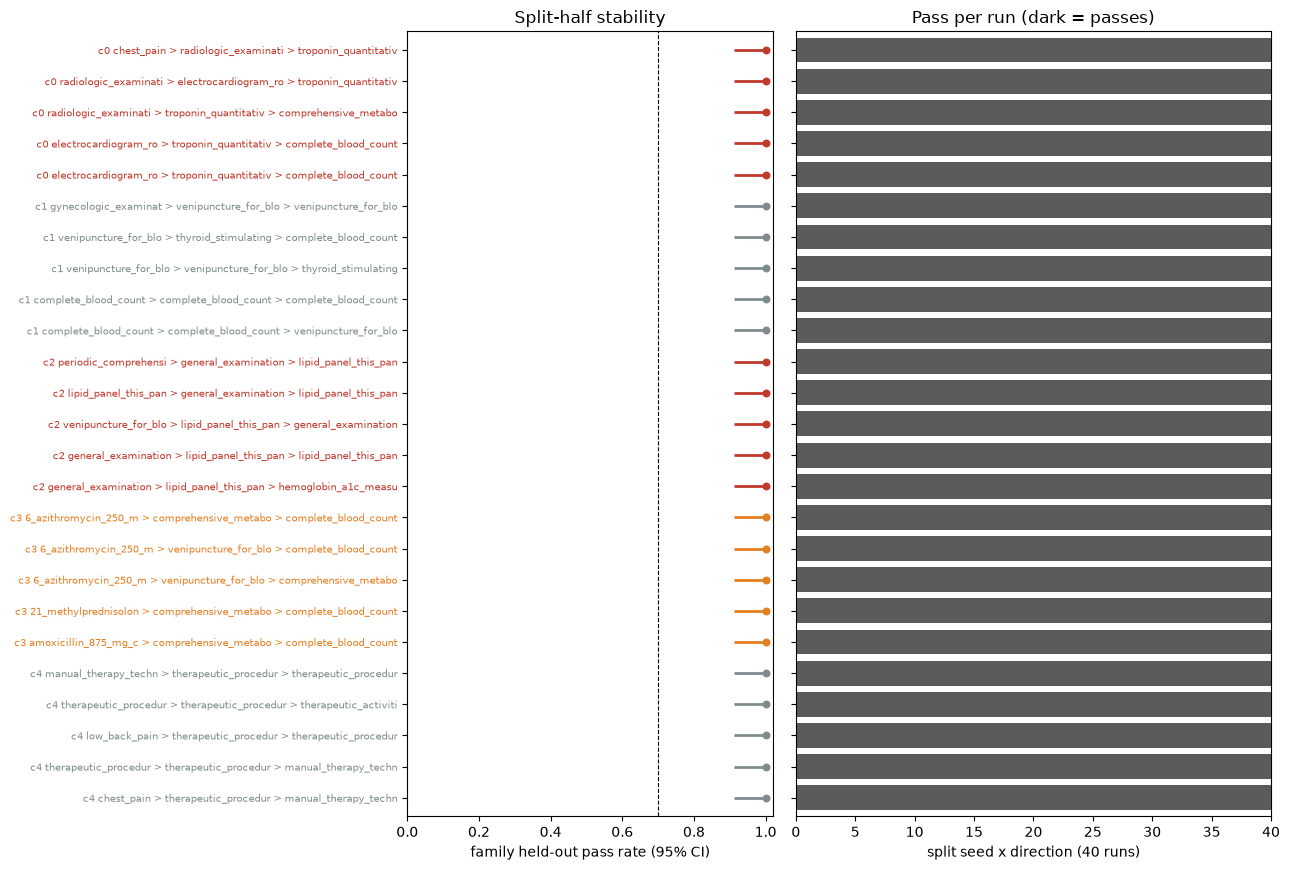

In [10]:
TOP_N = 5
GC = {CARD: '#C0392B', NONC: '#2A9D8F', RX: '#E67E22', BG: '#7F8C8D'}
short = lambda pat: ' > '.join(t.split('__')[0] for t in pat.split(' -> '))   # drop vocabulary / concept-id suffix
sel = []
for c, (_, name, role) in COMP.items():
    d = rows[c]
    if len(d):
        for i in np.flatnonzero(d.is_family_rep.to_numpy())[:TOP_N]:
            sel.append((c, i, role, f"c{c} {short(d.pattern.iloc[i])}"))
y = np.arange(len(sel))[::-1]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.28 * len(sel) + 1.8), sharey=True, gridspec_kw={'width_ratios': [1, 1.3]})
for yy, (c, i, role, lab) in zip(y, sel):
    d = rows[c].iloc[i]
    ax.hlines(yy, d.fam_holdout_rate_lo, d.fam_holdout_rate_hi, color=GC[role], lw=2)
    ax.scatter(d.fam_holdout_rate, yy, color=GC[role], s=22, zorder=3)
    ax2.imshow(ho_runs[c][i][None, :].astype(float), extent=(0, 40, yy - .4, yy + .4), aspect='auto', cmap='Greys', vmin=0, vmax=1.4)
ax.axvline(HO_MIN_RATE_LO, ls='--', c='k', lw=.8); ax.set_xlim(0, 1.02)
ax.set_xlabel('family held-out pass rate (95% CI)'); ax.set_yticks(y); ax.set_yticklabels([s[3] for s in sel], fontsize=7)
for t, s in zip(ax.get_yticklabels(), sel): t.set_color(GC[s[2]])
ax2.set_xlim(0, 40); ax2.set_ylim(-.6, len(sel) - .4); ax2.set_xlabel('split seed x direction (40 runs)')
ax.set_title('Split-half stability'); ax2.set_title('Pass per run (dark = passes)')
plt.tight_layout(); plt.show()

Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c3** read as a workup path (troponin, EKG, imaging, angiography, in that order) and does
  **c0** read as a slower outpatient path (EKG, stress test, labs)?
- Do `anxiety` / `panic_attack` show up as a motif *before* troponin in **c3**, or only after it?
  Without visits, a "panic in the ED" story has to be carried by the workup codes alone.
- Do the background bundles (c2, c5, c6, c7) stay generic?

### A second lens: the Day 1 psych / cardiac probe

`chest_pain_labels()` is a direct rule-based split built from corroborating co-evidence. It is a
probe, not the structure: the labels come from `PSYCH_TAGS` / `CARDIAC_TAGS`, so a motif made of
those same tags partly rediscovers the label rule. Mined on a random 5,000-patient sample, since
every candidate is scanned against every sequence.


In [11]:
weak = eo.chest_pain_labels(events)
wl   = weak.set_index('person_id').chest_pain_label

# All patients here have chest_pain by cohort construction, so no filtering needed. LOCAL mining on a
# fixed random sample: candidates x sequences scans are the cost on a cohort this size.
rng   = np.random.default_rng(0)
samp  = rng.choice(len(db), min(5_000, len(db)), replace=False)
db_s  = [db[i] for i in samp]
y_s   = np.array([wl.get(pids[i], 'unlabelled') for i in samp])
print("sampled patients:", len(db_s),
      "  labelled:", int((y_s != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_s, return_counts=True))))

pats_cp = prefixspan(db_s, max(3, int(0.08 * len(db_s))), max_len=4)
C_cp = [tuple(p) for p in pats_cp[pats_cp.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['psych', 'cardiac']:
    print(f"\n=== {g} evidence")
    display(discriminative(y_s == g, C_cp, sequences_db=db_s, min_in=0.10).head(6))


chest_pain patients: 139416   labelled: 65235   both-evidence (dropped): 37617   no-evidence (dropped): 36564
sampled patients: 5000   labelled: 2402    {np.str_('cardiac'): np.int64(1419), np.str_('psych'): np.int64(983), np.str_('unlabelled'): np.int64(2598)}

=== psych evidence


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> venipun...,0.378,0.439,0.9
1,general_examination___procedure__4036803 -> ve...,0.360,0.402,0.9
2,venipuncture_for_blo__procedure__4102442 -> li...,0.369,0.435,0.9
3,chest_pain__clinical_finding__77670 -> lipid_p...,0.295,0.391,0.8
4,chest_pain__clinical_finding__77670 -> lipid_p...,0.314,0.383,0.8
5,chest_pain__clinical_finding__77670 -> venipun...,0.340,0.444,0.8



=== cardiac evidence


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> compreh...,0.579,0.440,1.3
1,chest_pain__clinical_finding__77670 -> venipun...,0.497,0.402,1.2
2,chest_pain__clinical_finding__77670 -> venipun...,0.509,0.416,1.2
3,chest_pain__clinical_finding__77670 -> venipun...,0.431,0.345,1.2
4,complete_blood_count__procedure__4319466 -> co...,0.470,0.390,1.2
5,complete_blood_count__procedure__4319466 -> ve...,0.445,0.367,1.2


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A the same week" versus "A two years before B,"
which is the actual dx_9487 discriminator: is the anxiety history old and unrelated, or did
a cardiac workup follow within days. Allen's interval algebra defines 13 relations; for
point events on dates, a **signed gap** carries most of the value.

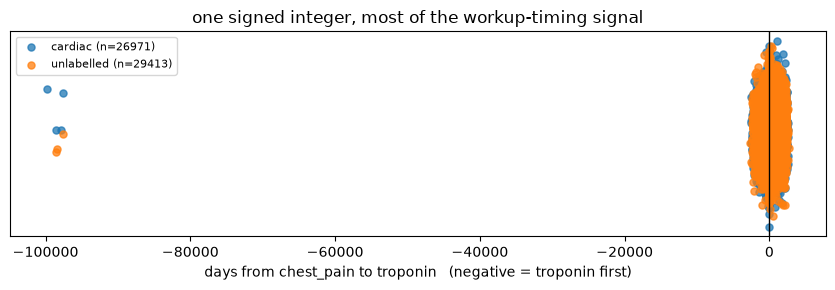

,count,mean,50%
chest_pain_label,,,
cardiac,26971.0,65.0,0.0
unlabelled,29413.0,97.0,0.0


In [12]:
gaps = eo.signed_gap(events, 'chest_pain', 'troponin')
gaps = gaps.merge(weak, on='person_id', how='left')
gaps['chest_pain_label'] = gaps['chest_pain_label'].fillna('unlabelled')

plt.figure(figsize=(8.5, 3))
for name, g in gaps.groupby('chest_pain_label'):
    plt.scatter(g.days_a_to_b, np.random.normal(0, .05, len(g)),
                s=26, alpha=.75, label=f"{name} (n={len(g)})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from chest_pain to troponin   (negative = troponin first)')
plt.legend(fontsize=8); plt.title('one signed integer, most of the workup-timing signal')
plt.tight_layout(); plt.show()

display(gaps.groupby('chest_pain_label').days_a_to_b
            .describe()[['count', 'mean', '50%']].round(0))

**One signed integer.** Worth remembering the next time the conversation turns to four weeks
of GPU pretraining.

Two cautions on real data. This feature is only meaningful where lookback covers the earlier
event — otherwise you are measuring enrolment, not biology. And for patients with no
troponin at all the feature is NULL, which is not the same as zero; carry an explicit
`no_workup_in_lookback` flag rather than imputing (this is exactly what
`cardiac_workup_outcome()` does formally in Day 5).



### 3b · Does psych evidence come before or after troponin?

Motif mining only surfaces patterns above a support floor, and psychiatric care is a minority inside
every bundle, so it can miss exactly this question. This asks it directly, with no floor: for each
patient with both, the days from their first psych evidence to their first troponin.

- **Psych evidence** = an anxiety or panic diagnosis, or a psychiatric evaluation / psychotherapy code
  (`psych_eval_therapy`). SSRIs and benzodiazepines are left out: they are prescribed for many reasons.
- Positive = psych evidence **first**, then troponin. Negative = troponin first.
- Patients with psych evidence and no troponin are not in this comparison (no workup in the data).
- Only meaningful where history covers the earlier event, as in section 3.


,n,psych first %,same day %,troponin first %,median days
ALL (psych + troponin),27046.0,57.2,7.4,35.4,108.0
"c0 acute / ED cardiac workup (ECG, tr",9126.0,53.2,8.5,38.3,34.0
c2 outpatient cardiometabolic / preve,7442.0,55.1,8.0,37.0,78.0
c1 women's health and genitourinary (,4503.0,63.5,5.5,31.0,215.0
c3 acute-illness prescriptions (stero,3362.0,58.6,8.3,33.1,153.0
c4 musculoskeletal / physical therapy,2613.0,65.1,3.8,31.0,292.0


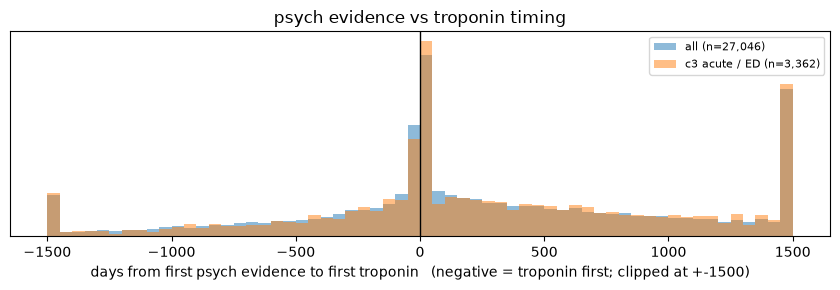

In [13]:
PSYCH = ['anxiety', 'panic_attack', 'psych_eval_therapy']
ev    = events[['person_id', 'event_date', 'concept_id', 'groups']]                  # no copy of the full frame
first = lambda tags: ev.loc[eo.group_mask(ev, tags)].groupby('person_id').event_date.min()

both = pd.concat([first(PSYCH).rename('psych'), first(['troponin']).rename('trop')], axis=1).dropna()
both['days_psych_to_trop'] = (both.trop - both.psych).dt.days
both['bundle'] = pd.Series(comp, index=pids).reindex(both.index)
both = both[both.bundle >= 0]                                   # drop patients with no assigned bundle

def timing(d):
    g = d.days_psych_to_trop
    return pd.Series({'n': len(d), 'psych first %': round((g > 0).mean() * 100, 1),
                      'same day %': round((g == 0).mean() * 100, 1),
                      'troponin first %': round((g < 0).mean() * 100, 1),
                      'median days': g.median()})

tab = both.groupby('bundle').apply(timing)
tab.index = [f"c{int(b)} {COMP[int(b)][1][:34]}" for b in tab.index]
tab.loc['ALL (psych + troponin)'] = timing(both)
display(tab.sort_values('n', ascending=False))

c3d = both[both.bundle == 3].days_psych_to_trop
plt.figure(figsize=(8.5, 3))
plt.hist(both.days_psych_to_trop.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"all (n={len(both):,})")
plt.hist(c3d.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"c3 acute / ED (n={len(c3d):,})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from first psych evidence to first troponin   (negative = troponin first; clipped at +-1500)')
plt.legend(fontsize=8); plt.title('psych evidence vs troponin timing')
plt.tight_layout(); plt.show()


## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is the closest thing
to a chest-pain triage flowchart, but derived from observed transitions rather than a
guideline document — Ethos has no chest-pain ruleset to start from, so the agreed method is
to start from the data and check clinical plausibility afterwards.

139416 chest pain patients
13 nodes, 79 edges


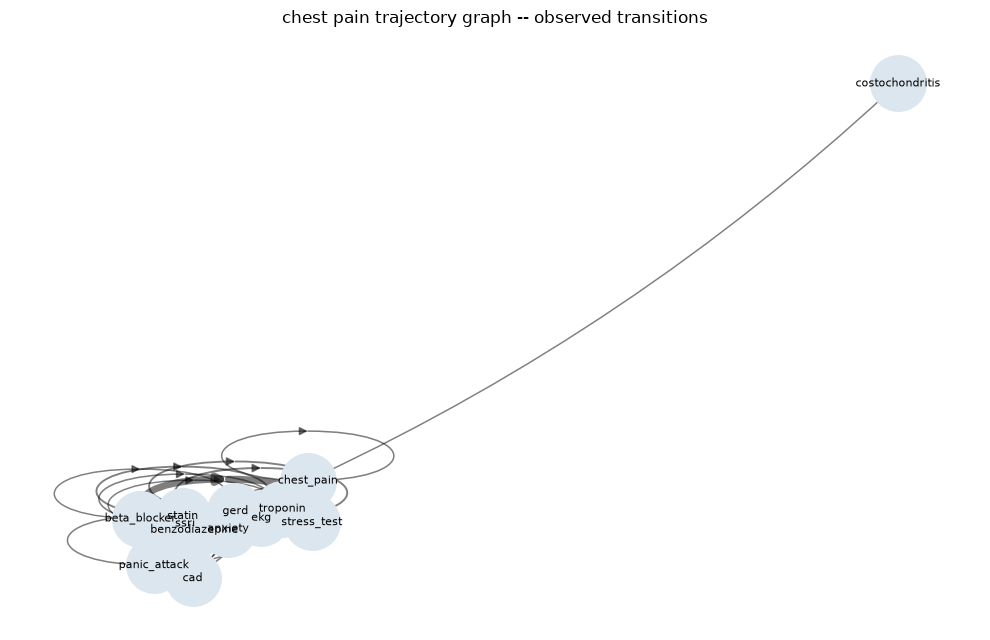

In [20]:
import networkx as nx

FOCUS = {'chest_pain', 'ekg', 'troponin', 'stress_test',
         'coronary_angio', 'beta_blocker', 'statin', 'cad',
         'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'gerd', 'costochondritis'}

# the graph is about curated clinical steps: relabel each concept token by its group, drop uncurated ones, collapse repeats
import itertools
_tg = events.drop_duplicates('tag').dropna(subset=['groups']).set_index('tag')['groups'].astype(str).str.split('|').to_dict()   # token -> ALL its groups
gseqs = {p: [g for g, _ in itertools.groupby(g for t in seqs[p] for g in _tg.get(t, ()))] for p in pids}
db_cp = [[c for c in gseqs[p] if c in FOCUS] for p in pids if 'chest_pain' in gseqs[p]]
print(f"{len(db_cp)} chest pain patients")

cnt = collections.Counter()
for s in db_cp:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_cp))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")


### Trajectory graph on a time axis
x = median days from the first chest pain to the first time the patient has that group (negative = before it), y = the component group that owns the tag's NMF loading. Nodes in a lane are staggered by x, so labels cannot overlap. The cell above only builds the transitions (`G`).

In [ ]:
# Trajectory graph on a time axis: x = median days from the patient's first chest pain to the first time the patient has that group
# (log-compressed, 0 = chest pain), y = the component group that owns the tag's NMF loading. Nodes in one lane are staggered by x, so labels cannot overlap.
# Edges are the transitions in G (cell above). Needs the graph cell above and the dated sequences (patseqs) from the hybrid section.
ANCHOR      = 'chest_pain'
ANCHOR_NAME = ANCHOR.replace('_', ' ')
MIN_N       = 20                                                   # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                          # vertical stagger step (y units), room one label needs on the x axis (inches)

_nodes  = set(G.nodes())
_have   = [i for i, p in enumerate(pids) if ANCHOR in gseqs[p]]     # the cohort of the graph
_first  = {n: [] for n in _nodes}
_a_tok  = {t for t, gs in _tg.items() if ANCHOR in gs}
for i in _have:
    ps = patseqs[i]
    a0 = min((ps.dpos[t][0] for t in _a_tok if t in ps.dpos), default=None)
    if a0 is None:
        continue
    best = {}
    for t, dl in ps.dpos.items():
        for g in _tg.get(t, ()):
            if g in _nodes and (g not in best or dl[0] < best[g]):
                best[g] = dl[0]
    for g, d in best.items():
        _first[g].append(d - a0)
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
med[ANCHOR] = 0.0

Hg_    = Hg if 'Hg' in globals() else eo.group_loadings(H, events)
comps_ = list(dict.fromkeys(v[2] for v in COMP.values()))           # component groups, in COMP order
def owner_lane(g):
    if g == ANCHOR:
        return 'anchor'
    if g not in Hg_.columns or Hg_[g].sum() == 0:
        return 'not in NMF'
    share = {l: Hg_.loc[[k for k, v in COMP.items() if v[2] == l], g].sum() / Hg_[g].sum() for l in comps_}
    return max(share, key=share.get)
lane_of  = {n: owner_lane(n) for n in _nodes}
LANES    = [l for l in comps_ + ['anchor', 'not in NMF'] if l in set(lane_of.values())]
_pal     = ['#2f855a', '#c05621', '#718096', '#2b6cb0', '#b83280', '#b7791f']
LANE_COL = {**{l: _pal[i % len(_pal)] for i, l in enumerate(comps_)}, 'anchor': '#d69e2e', 'not in NMF': '#a0aec0', **globals().get('GCOL', {})}

tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0           # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                      # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}            # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL.get(l, '#e2e8f0'), alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[LANE_COL.get(lane_of[n], '#e2e8f0') for n in G.nodes()], edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, {n: (x, y - 0.42) for n, (x, y) in pos_t.items()}, ax=ax, font_size=8,
                        bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)              # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else ANCHOR_NAME for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel(f"median days from first {ANCHOR_NAME} to first occurrence of the group (log-compressed)")
ax.set_title(f'{ANCHOR_NAME} trajectory graph on a time axis -- lanes = owning component group')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: int(sum(1 for n in _nodes if lane_of[n] == l)) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")


**How to read it.** Left to right is time: each tag sits at the median number of days between the patient's first chest pain and the first time they have that tag (log-compressed; left = before chest pain, right = after, the dashed line is chest pain). Each row (lane) is the NMF component role that owns most of the tag's loading (cardiac workup, drug domain, non-cardiac explanation or background, as set in `COMP`). `chest_pain` has its own lane because it is the cohort anchor and not in the NMF; a tag too rare to reach the NMF goes to a "not in NMF" lane. Tags inside a lane are staggered up and down only so the labels do not overlap: the vertical offset has no meaning. A tag with fewer than 20 patients who have both it and chest pain has no timing and is parked at the right edge. Positions use the *first* occurrence, so a tag that repeats (ECG, statin) can look earlier than the episode next to chest pain. A lane is a loading share, not a diagnosis. Arrows are the observed transitions between consecutive curated steps; thicker = more patients.

Two arms should be visible out of `chest_pain`: one through troponin, stress test,
angiography and statins; the other through anxiety, panic_attack, ssri and benzodiazepine.
Whichever arm dominates numerically is the answer to the working hypothesis — let the graph
say which, rather than assuming.

## Exercises

1. Lower `MIN_SUP` to 1%. How many patterns, and is closed-pattern pruning enough?
2. Extend `prefixspan` to enforce a maximum time gap between consecutive items. Which
   patterns die? (This is the single highest-value extension for claims.)
3. Add `gerd` and `costochondritis` to the trajectory graph's `FOCUS` set with a lower edge
   threshold. Do either show up as a real third arm, or are they noise?
4. Re-run the whole notebook with `tag_events(..., fallback='drop')` so only curated
   codesets survive. Cleaner patterns, but what did you lose?
5. Write the top motif per group (psych, cardiac) as a named plain-English rule. **That
   list is the motif catalog** — the thing to actually put in front of RUW.

## Carry forward

A motif catalog for dx_9487 triage, obtained without a foundation model.

## 5 · Final table — one per experiment (Excel)
One row per ordered pattern, grouped by NMF bundle in order c0, c1, ... The bundle's size and top-5 OMOP entities come from the NMF loaded from the Day 1 v3 cache. UW suggestion, supported literature (drop-down) and PMIDs are left empty for the review; supported literature and PMIDs are the last two columns. Written next to this notebook; needs `openpyxl`.

In [21]:
COHORT = 'chestpain'
# ONE condensed final table per experiment: bundles in NMF order (c0, c1, ...), each with its top-5 OMOP entities and its top-TOPK ordered patterns.
# Uses the NMF loaded above (cache from Day1_nmf_v3), not a refit. The literature / PMID / pathway / UW columns are left for the review.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"Day3_v3_concept_final_table_{COHORT}_k{K}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', 'Share of group with pattern', 'Share of everyone else with pattern', 'Held-out pass rate (family, 40 splits)', 'Holds up on held-out halves?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 12)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle)" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} · {COMP[c][1]}", f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    d = hyb[c].head(TOPK) if len(hyb.get(c, [])) else hyb[c].iloc[0:0] if c in hyb else None
    if d is None or not len(d):
        table.append((c, head + [''] * (len(HEAD) - 3)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        ok = r.fam_holdout_rate_lo >= HO_MIN_RATE_LO
        verdict = 'Unstable' if not ok else ('Suggestive' if r.same_day_bundle else 'Solid')
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), float(r.sup_in), float(r.sup_out), float(r.fam_holdout_rate), 'Yes' if ok else 'No',
                                                     float(r.lift), verdict, '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 12}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (6, 7, 8): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 10).number_format = '0.0'
    for j in (9, 11, 13):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 14))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 14, 70, 8, 80, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: Day 3 v3 concept, chestpain run, NMF k={K} on concept-level tokens (Day 1 v3, loaded from cache), {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK} highest-lift ordered patterns of each bundle, taken from its most common ordered patterns of 3+ steps (each present in >={REL_SUP:.0%} of the bundle). Several are variants of one pathway.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    f"Held-out pass rate: {len(HO_SEEDS)} random 50/50 splits of the whole bundle x 2 directions = {2 * len(HO_SEEDS)} runs; a run passes if, on the half not used, support is >= {REL_SUP:.0%} and the lower 95% bound of the odds ratio vs all other patients is >= {HO_MIN_OR:g}. Near-duplicate patterns are one family (a run passes if any member does). Holds = family lower 95% bound >= {HO_MIN_RATE_LO:.0%}.",
    "Final verdict (chest pain has no bootstrap / re-test run, so the held-out result is used): Solid = holds and order shown by dates; Suggestive = holds but a same-day bundle; Unstable = does not hold.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :11]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/Day3_v3_concept_final_table_chestpain_k5.xlsx  (5 bundles, 15 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Share of group with pattern,Share of everyone else with pattern,"Held-out pass rate (family, 40 splits)",Holds up on held-out halves?,Times as common (lift),Final verdict
0,"c0 · acute / ED cardiac workup (ECG, troponin,...","25,953 (18.6%)","1. Electrocardiogram, routine ECG with… [CPT4 ...",1,Chest pain [SNOMED 29857009] → Radiologic exam...,0.481,0.159,1.0,Yes,2.9,Suggestive
1,,,,2,"Radiologic examination, chest [CPT4 71045] → E...",0.501,0.167,1.0,Yes,2.9,Suggestive
2,,,,3,"Radiologic examination, chest [CPT4 71045] → E...",0.497,0.174,1.0,Yes,2.8,Suggestive
3,c1 · women's health and genitourinary (gyn exa...,"17,669 (12.7%)",1. Gynecologic examination [SNOMED 83607001] (...,1,Gynecologic examination [SNOMED 83607001] → Ve...,0.491,0.069,1.0,Yes,6.4,Solid
4,,,,2,Venipuncture for blood test [SNOMED 28520004] ...,0.505,0.267,1.0,Yes,1.9,Solid
5,,,,3,Venipuncture for blood test [SNOMED 28520004] ...,0.506,0.265,1.0,Yes,1.9,Solid
6,c2 · outpatient cardiometabolic / preventive c...,"54,581 (39.1%)",1. Lipid panel [CPT4 80061] (84% of bundle)\n2...,1,Periodic comprehensive preventive… [CPT4 99396...,0.480,0.183,1.0,Yes,2.5,Solid
7,,,,2,Lipid panel [CPT4 80061] → General examination...,0.471,0.195,1.0,Yes,2.3,Solid
8,,,,3,Venipuncture for blood test [SNOMED 28520004] ...,0.484,0.208,1.0,Yes,2.3,Solid
9,"c3 · acute-illness prescriptions (steroids, an...","26,712 (19.2%)",1. {21 (methylprednisolone 4 MG Oral… [RxNorm ...,1,{6 (azithromycin 250 MG Oral Tablet)… [RxNorm ...,0.202,0.059,1.0,Yes,3.1,Solid


## 5b · Anchor-focused view — top chest pain sequences and where they rank
Additional to the table above (which stays as is): the same bundles, but only ordered patterns that contain a chest pain step, with their rank among the bundle's scored top patterns (by lift and by support). Post-filter of the scored candidates, no re-mining, so every score and verdict is the one in the main table. Writes its own xlsx.

In [22]:
COHORT = 'chestpain'
# ANCHOR-FOCUSED view of the final table (additional; the table above is untouched): per bundle, the top-TOPK_ANCHOR scored ordered patterns that contain a chest_pain step,
# with the position of that step (k of n). Same scores / verdicts as the table above (post-filter of hyb, no re-mining). Own xlsx file; Triage / literature / PMIDs left empty.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"Day3_v3_concept_anchor_table_{COHORT}_k{K}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

ANCHOR      = 'chest_pain'                                                    # cohort anchor group (codesets.yaml)
ANCHOR_NAME = ANCHOR.replace('_', ' ')
ANCHOR_TOK  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])    # every concept-level token that belongs to the anchor group
TOPK_ANCHOR = 3                                                       # anchor patterns per bundle (highest lift first)

def has_anchor(pattern):
    return any(t in ANCHOR_TOK for t in pattern.split(' -> '))

_a0 = {}
def offset_text(c, members, t, min_n=20):
    """Median days from each patient's first {ANCHOR} step to their first occurrence of token t (negative = t came first), over the bundle's patients who have both."""
    if c not in _a0:                                                       # first anchor day per member, computed once per bundle
        _a0[c] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[c])[~np.isnan(td - _a0[c])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    med = int(np.median(g))
    when = "same day as" if med == 0 else f"{abs(med):,} d {'before' if med < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Held-out pass rate (family, 40 splits)', 'Holds up on held-out halves?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle){offset_text(c, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} · {COMP[c][1]}", f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    pool  = hyb.get(c)
    pool  = pool if pool is not None and len(pool) else None
    if pool is not None:
        pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # hyb[c] is lift-sorted
        has  = pool.pattern.map(has_anchor)
    d     = pool[has].head(TOPK_ANCHOR) if pool is not None else None
    head[1] += f"\n{int(has.sum()) if pool is not None else 0} of {len(pool) if pool is not None else 0} scored patterns contain {ANCHOR_NAME}"
    if d is None or not len(d):
        table.append((c, head + ['', f"no scored pattern contains {ANCHOR_NAME} (bundle has {len(pool) if pool is not None else 0} scored patterns)"] + [''] * (len(HEAD) - 5)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        ok = r.fam_holdout_rate_lo >= HO_MIN_RATE_LO
        verdict = 'Unstable' if not ok else ('Suggestive' if r.same_day_bundle else 'Solid')
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), float(r.fam_holdout_rate), 'Yes' if ok else 'No',
                                                     float(r.lift), verdict, '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8, 9): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: Day 3 v3 concept, chestpain run, NMF k={K} on concept-level tokens (Day 1 v3, loaded from cache), {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK_ANCHOR} highest-lift scored ordered patterns of each bundle that contain a {ANCHOR_NAME} step (any {ANCHOR_NAME} concept), from the same candidates as the main table (ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the bundle). The second line of each n (%) cell says how many of the bundle's scored patterns contain {ANCHOR_NAME}.",
    f"Entities: under each entity, the median number of days from the patient's first {ANCHOR_NAME} step to their FIRST occurrence of that entity (before / after), over the bundle patients who have both, and the share of them for whom it came first. Repeated entities (labs, drugs) are read at their first occurrence.",
    "Position among the bundle's scored top patterns: each bundle's candidates are its 100 most frequent ordered patterns (3+ steps) that pass the support floor, scored for lift; the pattern's place in that list by lift (1 = most specific to the bundle) and by support (1 = most frequent), out of the N patterns scored. A bundle with no such pattern is shown as such, not filled.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    f"Held-out pass rate: {len(HO_SEEDS)} random 50/50 splits of the whole bundle x 2 directions = {2 * len(HO_SEEDS)} runs; a run passes if, on the half not used, support is >= {REL_SUP:.0%} and the lower 95% bound of the odds ratio vs all other patients is >= {HO_MIN_OR:g}. Near-duplicate patterns are one family (a run passes if any member does). Holds = family lower 95% bound >= {HO_MIN_RATE_LO:.0%}.",
    "Final verdict (chest pain has no bootstrap / re-test run, so the held-out result is used): Solid = holds and order shown by dates; Suggestive = holds but a same-day bundle; Unstable = does not hold.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/Day3_v3_concept_anchor_table_chestpain_k5.xlsx  (5 bundles, 15 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Position in the bundle's scored top patterns (by lift · by support),Share of group with pattern,Share of everyone else with pattern,"Held-out pass rate (family, 40 splits)",Holds up on held-out halves?,Times as common (lift),Final verdict
0,"c0 · acute / ED cardiac workup (ECG, troponin,...","25,953 (18.6%)\n24 of 60 scored patterns conta...","1. Electrocardiogram, routine ECG with… [CPT4 ...",1,Chest pain [SNOMED 29857009] → Radiologic exam...,1 of 60 by lift · 54 of 60 by support,0.481,0.159,1.0,Yes,2.9,Suggestive
1,,,,2,Chest pain [SNOMED 29857009] → Electrocardiogr...,6 of 60 by lift · 5 of 60 by support,0.644,0.246,1.0,Yes,2.6,Suggestive
2,,,,3,Chest pain [SNOMED 29857009] → Electrocardiogr...,7 of 60 by lift · 29 of 60 by support,0.520,0.197,1.0,Yes,2.6,Suggestive
3,c1 · women's health and genitourinary (gyn exa...,"17,669 (12.7%)\n6 of 60 scored patterns contai...",1. Gynecologic examination [SNOMED 83607001] (...,1,Chest pain [SNOMED 29857009] → Venipuncture fo...,34 of 60 by lift · 20 of 60 by support,0.543,0.380,0.0,No,1.4,Unstable
4,,,,2,Venipuncture for blood test [SNOMED 28520004] ...,42 of 60 by lift · 44 of 60 by support,0.503,0.356,0.0,No,1.4,Unstable
5,,,,3,Chest pain [SNOMED 29857009] → Venipuncture fo...,49 of 60 by lift · 27 of 60 by support,0.533,0.400,0.0,No,1.3,Unstable
6,c2 · outpatient cardiometabolic / preventive c...,"54,581 (39.1%)\n7 of 60 scored patterns contai...",1. Lipid panel [CPT4 80061] (84% of bundle)\n ...,1,Venipuncture for blood test [SNOMED 28520004] ...,21 of 60 by lift · 32 of 60 by support,0.492,0.273,1.0,Yes,1.8,Solid
7,,,,2,Chest pain [SNOMED 29857009] → Lipid panel [CP...,23 of 60 by lift · 24 of 60 by support,0.507,0.287,1.0,Yes,1.7,Solid
8,,,,3,Chest pain [SNOMED 29857009] → Venipuncture fo...,24 of 60 by lift · 6 of 60 by support,0.568,0.329,1.0,Yes,1.7,Solid
9,"c3 · acute-illness prescriptions (steroids, an...","26,712 (19.2%)\n20 of 60 scored patterns conta...",1. {21 (methylprednisolone 4 MG Oral… [RxNorm ...,1,Chest pain [SNOMED 29857009] → Comprehensive m...,6 of 60 by lift · 1 of 60 by support,0.302,0.518,0.0,No,0.6,Unstable


## 6 · Export — token map
One row per token. At concept level a token **is** one OMOP concept, so this is the join table for later pipelines: `token` → `concept_id`, vocabulary, code, name, domain, every codeset it belongs to (`groups`), event / patient counts, whether it is in the NMF and which component owns it, and in how many motifs it appears. Written next to this notebook.

In [17]:
# token map: one row per token (= one OMOP concept at concept level) so later pipelines can join on concept_id instead of parsing names
TOKEN_MAP = f"token_map_chestpain_concept.csv"
assert events.groupby('tag').concept_id.nunique().eq(1).all(), "a token maps to more than one concept_id"
first = events.drop_duplicates('tag').set_index('tag')
cnt   = events.groupby('tag').person_id.agg(n_events='size', n_patients='nunique')
keep  = [c for c in ('concept_id', 'concept_name', 'vocabulary_id', 'concept_code', 'concept_class_id', 'domain') if c in first.columns]
tm    = first[keep].join(cnt)
tm['groups']      = first['groups'].astype(str).where(first['groups'].notna(), '')            # every codeset the concept is in, '|'-joined
tm['in_nmf']      = tm.index.isin(H.columns)
tm['nmf_owner']   = H.idxmax(axis=0).reindex(tm.index).astype('Int64')                        # component with the largest loading (blank = not in the NMF)
tm['owner_share'] = (H.max(axis=0) / H.sum(axis=0)).reindex(tm.index).round(3)
_in_motifs = collections.Counter(t for d in hyb.values() if len(d) for p in d.pattern for t in set(p.split(' -> ')))
tm['n_motifs']    = tm.index.map(lambda t: _in_motifs.get(t, 0))
tm = tm.rename_axis('token').reset_index().sort_values(['n_patients', 'token'], ascending=[False, True])
tm.to_csv(TOKEN_MAP, index=False)
print(f"wrote {os.path.abspath(TOKEN_MAP)}: {len(tm):,} tokens | {int(tm.in_nmf.sum()):,} in the NMF | {int((tm.n_motifs > 0).sum()):,} appear in a motif | {int((tm.groups != '').sum()):,} belong to a codeset")
tm.head(8)

wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/token_map_chestpain_concept.csv: 27,743 tokens | 9,542 in the NMF | 22 appear in a motif | 401 belong to a codeset


,token,concept_id,concept_name,vocabulary_id,concept_code,concept_class_id,domain,n_events,n_patients,groups,in_nmf,nmf_owner,owner_share,n_motifs
51,chest_pain__clinical_finding__77670,77670,Chest pain,SNOMED,29857009,Clinical Finding,Condition,410204,133792,chest_pain,False,<NA>,NaN,62
105,venipuncture_for_blo__procedure__4102442,4102442,Venipuncture for blood test,SNOMED,28520004,Procedure,Procedure,706804,100763,,True,2,0.416,153
18,comprehensive_metabo__procedure__3661905,3661905,Comprehensive metabolic panel,SNOMED,371361000119107,Procedure,Measurement,493339,95388,,True,2,0.372,125
8,complete_blood_count__procedure__4319466,4319466,Complete blood count with white cell different...,SNOMED,9564003,Procedure,Measurement,491353,94699,,True,0,0.357,130
0,lipid_panel_this_pan__cpt4__2212095,2212095,Lipid panel This panel must include the follow...,CPT4,80061,CPT4,Measurement,378338,89250,,True,2,0.554,70
68,general_examination___procedure__4036803,4036803,General examination of patient,SNOMED,162673000,Procedure,Procedure,296482,81244,,True,2,0.572,11
30,hemoglobin_a1c_measu__procedure__4184637,4184637,Hemoglobin A1c measurement,SNOMED,43396009,Procedure,Measurement,296668,72635,hba1c,True,2,0.541,13
56,electrocardiogram_ro__cpt4__2313816,2313816,"Electrocardiogram, routine ECG with at least 1...",CPT4,93010,CPT4,Procedure,190858,69292,ekg,True,0,0.639,17
